# Figure 3

In [14]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_behavioral_data,
    load_rtlme_interaction_avgpred,
    load_rtlme_interaction_contrasts,
    DATASET_CURRENCY,
    LOSS_AVERSION,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [17]:
def _fmt_tick(v):
    try:
        return f"{float(v):g}"
    except (ValueError, TypeError):
        return str(v)


def format_pvalue(p):
    """APA-style p-value: p<.001, else p=.XXX (leading zero dropped)."""
    if p < 0.001:
        return "p<.001"
    return f"p={p:.3f}".replace("0.", ".", 1)


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + 1.1*h, format_pvalue(p), ha="center", va="bottom",
            fontsize=12)


def _lookup_contrast(contrasts_df, label_a, label_b):
    """avg_comparisons() contrast labels follow factor level order, not
    argument order, so try both "A - B" and "B - A"."""
    for label in (f"{label_a} - {label_b}", f"{label_b} - {label_a}"):
        match = contrasts_df[contrasts_df["contrast"] == label]
        if len(match):
            return match.iloc[0]
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def get_transition_avgpred(avgpred_df, dataset, transition_label):
    row = avgpred_df[
        (avgpred_df["dataset"] == dataset) & (avgpred_df["transition"] == transition_label)
    ].iloc[0]
    return row["avgpred"], row["asymp.LCL"], row["asymp.UCL"]


def get_transition_contrast_pvalue(contrasts_df, dataset, label_a, label_b):
    ds_contrasts = contrasts_df[contrasts_df["dataset"] == dataset]
    return _lookup_contrast(ds_contrasts, label_a, label_b)["p.value"]


def plot_gain_loss_heatmap(ax, hmap_data, dataset, cmap, vmin, vmax, cbar_label,
                           show_loss_aversion=True):
    """Gain (rows) x loss (columns) heatmap, optionally with the gain =
    lambda * loss loss-aversion diagonal. hmap_data: index=loss, columns=gain."""
    losses = hmap_data.index.values.astype(float)
    gains  = hmap_data.columns.values.astype(float)
    hmap_t = hmap_data.T  # rows=gain, columns=loss

    sns.heatmap(
        hmap_t, cmap=cmap, square=True, linewidths=1, linecolor="black",
        vmin=vmin, vmax=vmax, cbar=True, cbar_kws={"label": cbar_label},
        ax=ax, xticklabels=True, yticklabels=True,
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(rotation=90)
    ax.invert_yaxis()  # gain increases from bottom to top

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

    if show_loss_aversion:
        lambd = LOSS_AVERSION.get(dataset)
        if lambd is not None:
            n_rows, n_cols = len(gains), len(losses)
            loss_endpoints = np.array([losses.min(), losses.max()])
            gain_endpoints = lambd * loss_endpoints
            loss_coords = (
                0.5 + (loss_endpoints - losses.min())
                / (losses.max() - losses.min()) * (n_cols - 1)
            )
            gain_coords = (
                0.5 + (gain_endpoints - gains.min())
                / (gains.max() - gains.min()) * (n_rows - 1)
            )
            ax.plot(loss_coords, gain_coords, color="black", linestyle="--", linewidth=4)

    currency = DATASET_CURRENCY.get(dataset, "")
    ax.set_xlabel(f"Loss ({currency})")
    ax.set_ylabel(f"Gain ({currency})")
    ax.set_xticklabels([_fmt_tick(v) for v in losses])
    ax.set_yticklabels([_fmt_tick(v) for v in gains])

### 1x3 figures: RT grids, RT estimated marginal means
Columns = datasets. Figure 1: mean RT across gain x loss. Figure 2: RT LME estimated marginal means (accept/reject x switch/repeat).

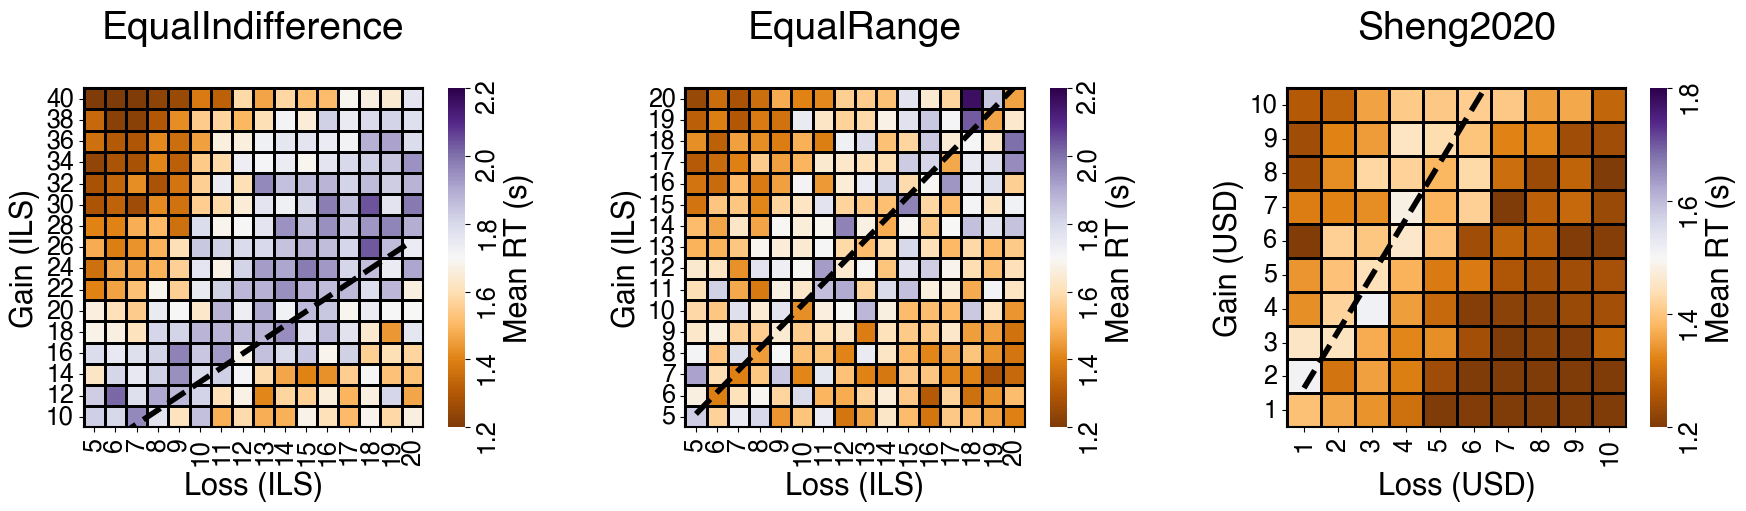

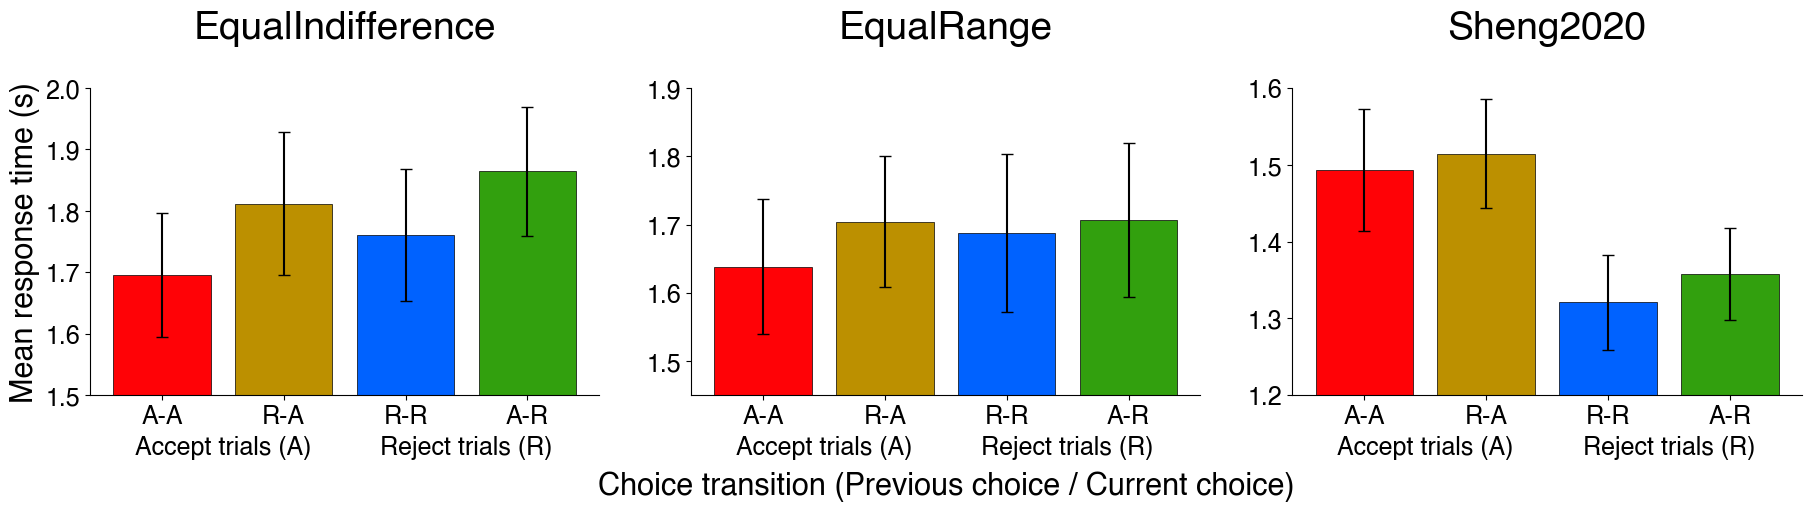

In [18]:
behavior_data = load_behavioral_data()
rtlme_interaction_avgpred = load_rtlme_interaction_avgpred()
rtlme_interaction_contrasts = load_rtlme_interaction_contrasts()

RT_CMAP = "PuOr"
RT_VLIMS = {
    "equalIndifference": (1.2, 2.2),
    "equalRange": (1.2, 2.2),
    "sheng2020": (1.2, 1.8),
}
RT_YLIMS = {
    "equalIndifference": (1.5, 2),
    "equalRange": (1.45, 1.9),
    "sheng2020": (1.2, 1.6),
}

BAR_ORDER = ["accept_to_accept", "reject_to_accept", "reject_to_reject", "accept_to_reject"]
BAR_COLORS = {
    "accept_to_accept": "#FF0206",
    "reject_to_accept": "#BC9000",
    "reject_to_reject": "#0062FF",
    "accept_to_reject": "#32A00E",
}
BAR_LABELS = {
    "accept_to_accept": "A-A",
    "reject_to_accept": "R-A",
    "reject_to_reject": "R-R",
    "accept_to_reject": "A-R",
}
# (x1, x2, label_a, label_b)
BRACKET_PAIRS = [
    (0, 1, "accept_to_accept", "reject_to_accept"),  # AA vs RA: within Prev. Accept
    (2, 3, "reject_to_reject", "accept_to_reject"),  # RR vs AR: within Prev. Reject
]

rt_hmaps = {}
for ds in DATASETS:
    ds_data = behavior_data[behavior_data["dataset"] == ds]
    subj_cell_means = ds_data.groupby(["sub", "loss", "gain"])["rt"].mean().reset_index()
    rt_hmaps[ds] = subj_cell_means.groupby(["loss", "gain"])["rt"].mean().unstack()


def set_dataset_titles(row_axes):
    for ax, ds in zip(row_axes, DATASETS):
        ax.set_title(f"{DATASET_LABELS.get(ds, ds)}\n", fontweight="bold")


# --- Row 1: mean RT across gain x loss ---
def draw_rt_grid_row(row_axes):
    for ax, ds in zip(row_axes, DATASETS):
        plot_gain_loss_heatmap(
            ax, rt_hmaps[ds], ds,
            cmap=RT_CMAP, vmin=RT_VLIMS[ds][0], vmax=RT_VLIMS[ds][1], cbar_label="Mean RT (s)",
        )


# --- Row 2: RT LME estimated marginal means ---
def draw_rt_emm_row(row_axes):
    x_pos = np.arange(len(BAR_ORDER))
    for col, (ax, ds) in enumerate(zip(row_axes, DATASETS)):
        vals = [get_transition_avgpred(rtlme_interaction_avgpred, ds, key) for key in BAR_ORDER]
        means, los, his = (np.array(v) for v in zip(*vals))

        ax.bar(x_pos, means, yerr=[means - los, his - means],
               color=[BAR_COLORS[key] for key in BAR_ORDER], capsize=4,
               edgecolor="black", linewidth=0.5, zorder=2)

        y_bracket = his.max()
        for x1, x2, label_a, label_b in BRACKET_PAIRS:
            p_val = get_transition_contrast_pvalue(rtlme_interaction_contrasts, ds, label_a, label_b)
            # add_significance_bracket(ax, x1, x2, y_bracket, 0.005 * y_bracket, p_val)

        ax.set_ylim(*RT_YLIMS[ds])
        ax.set_xticks(x_pos)
        ax.set_xticklabels([BAR_LABELS[key] for key in BAR_ORDER])
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Group labels below the x-axis (x in data coords, y in axes fraction)
        ax.text(0.5, -0.13, "Accept trials (A)", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=18)
        ax.text(2.5, -0.13, "Reject trials (R)", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=18)

        if col == 0:
            ax.set_ylabel("Mean response time (s)")
        else:
            ax.set_ylabel(" ")
        if col == 1:
            ax.set_xlabel("Choice transition (Previous choice / Current choice)", labelpad=30)


ROW_FIGURES = [
    ("rtgrid", draw_rt_grid_row),
    ("rtemm", draw_rt_emm_row),
]

for name, draw_row in ROW_FIGURES:
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5), layout="constrained")
    set_dataset_titles(axes)
    draw_row(axes)
    fig.savefig(f"saved/figure3_v2_{name}.svg", dpi=300, bbox_inches="tight")
    plt.show()